# PRISM: convergence and numerical behavior

Numerical results are read from `results/analysis/`. 


## Convergence summary

Uses the stored optimization traces. Trace quantiles describe variation between fits; they are not independent dataset uncertainty.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'runs/run_model.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from inside the repository.')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.cache/matplotlib'))
sys.path[:0] = [str(ROOT / 'analysis'), str(ROOT / 'runs')]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import final_visualization as fv
import result_tables as th
fv.apply_style()


### Convergence summary


,value
fits,2.250000e+02
finished,2.250000e+02
tolerance_stops,3.000000e+00
budget_stops,2.220000e+02
retries,0.000000e+00
h_final_median,2.435610e-11
h_final_max,8.392254e-08
relative_change_median,8.645255e-05
relative_change_q95,3.662893e-04
relative_change_max,5.598894e-04


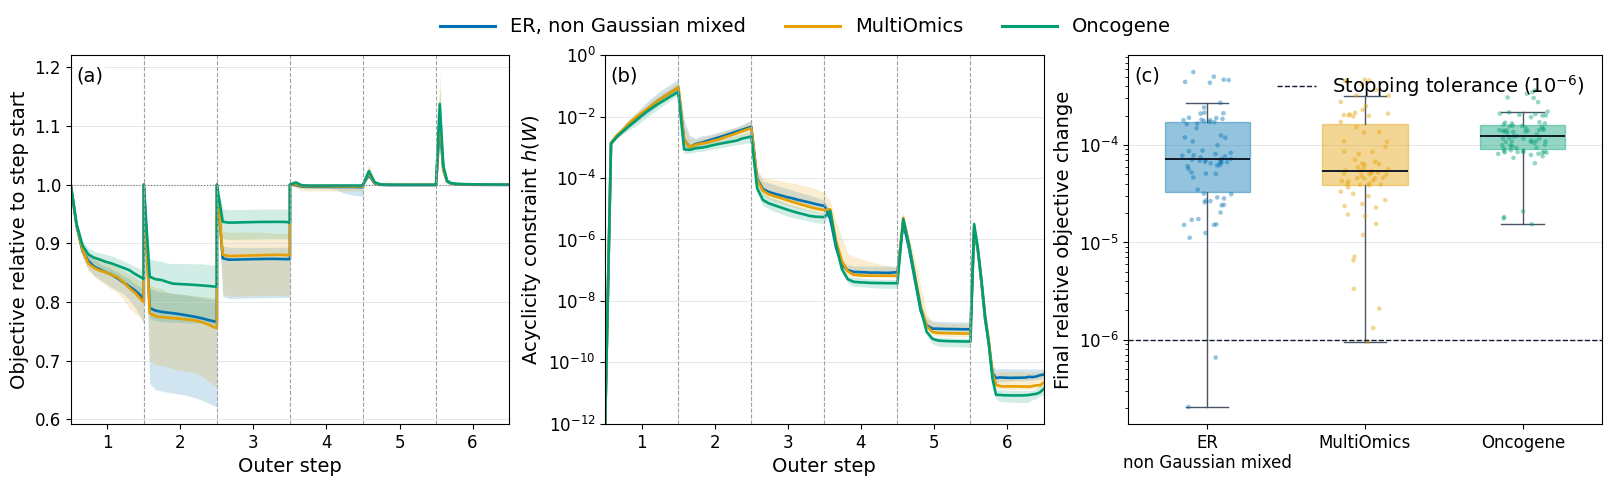

In [2]:
from prism_convergence_figure import plot_prism_convergence
fig_convergence, _, convergence_stats = plot_prism_convergence(prepared_data=pd.read_pickle(ROOT / "results/analysis/convergence.pkl"))
display(pd.Series(convergence_stats, name='value').to_frame())
display(fig_convergence)
plt.close(fig_convergence)


## Trajectories by family


### Fit diagnostics and trace quantiles


,family,progress,relative_objective_0.25,relative_objective_0.5,relative_objective_0.75,h_0.25,h_0.5,h_0.75
0,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.00000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
1,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.08000,0.815067,0.841814,0.859176,0.001920,0.002125,0.002343
2,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.16000,0.642301,0.659797,0.709245,0.004466,0.005050,0.005942
3,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.24000,0.562840,0.591411,0.640739,0.007623,0.009841,0.014006
4,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.32000,0.537126,0.569526,0.613823,0.014136,0.020202,0.030992
5,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.40000,0.518802,0.552919,0.595998,0.023736,0.040073,0.058659
6,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.48000,0.494697,0.533221,0.572199,0.042057,0.071815,0.113059
7,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.56000,0.456957,0.504112,0.556343,0.069859,0.127664,0.200980
8,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.64000,0.403786,0.460091,0.533506,0.111251,0.207643,0.325839
9,20nodes_ER_obsconf0_latconf0_Gaussian_Linear,0.72000,0.337028,0.404086,0.507031,0.189984,0.323932,0.485526


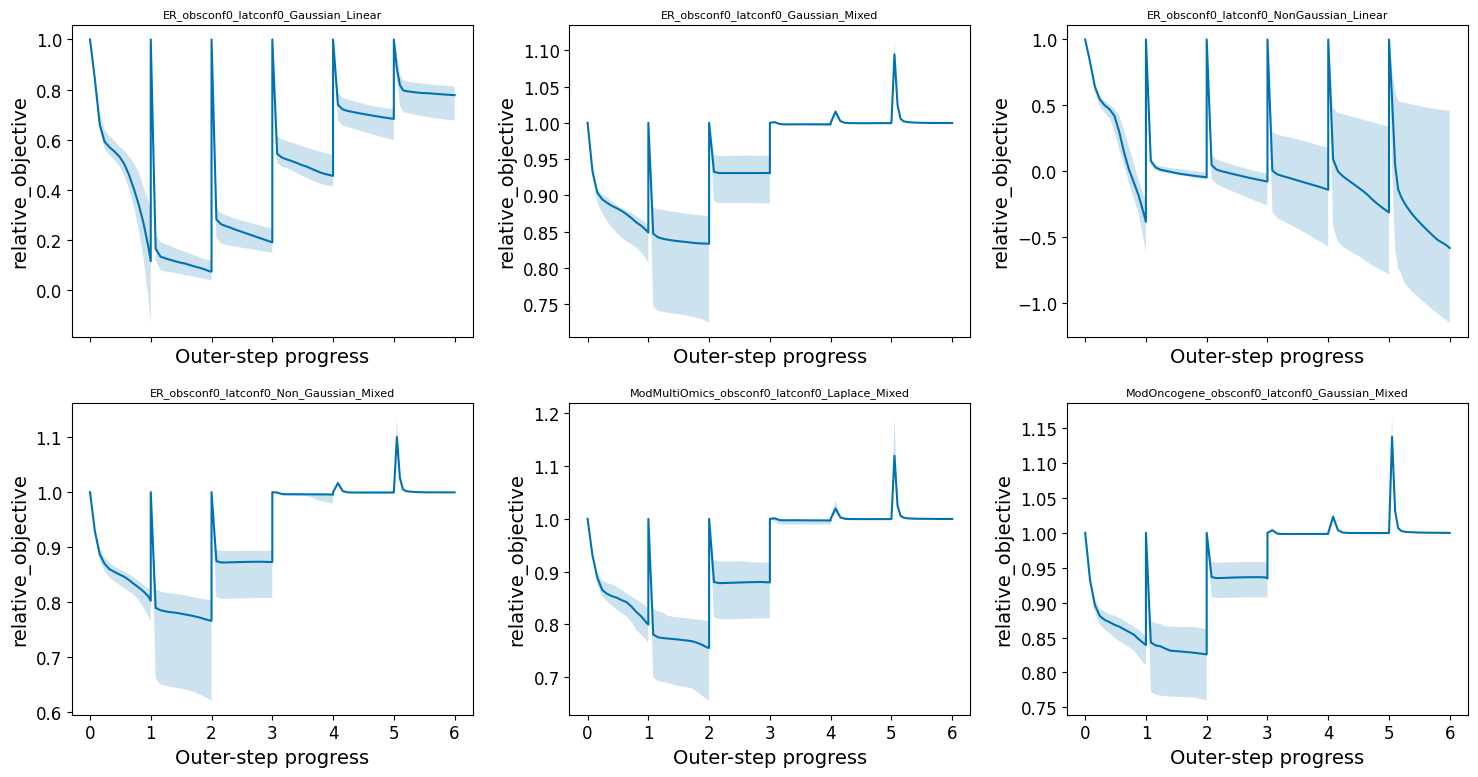

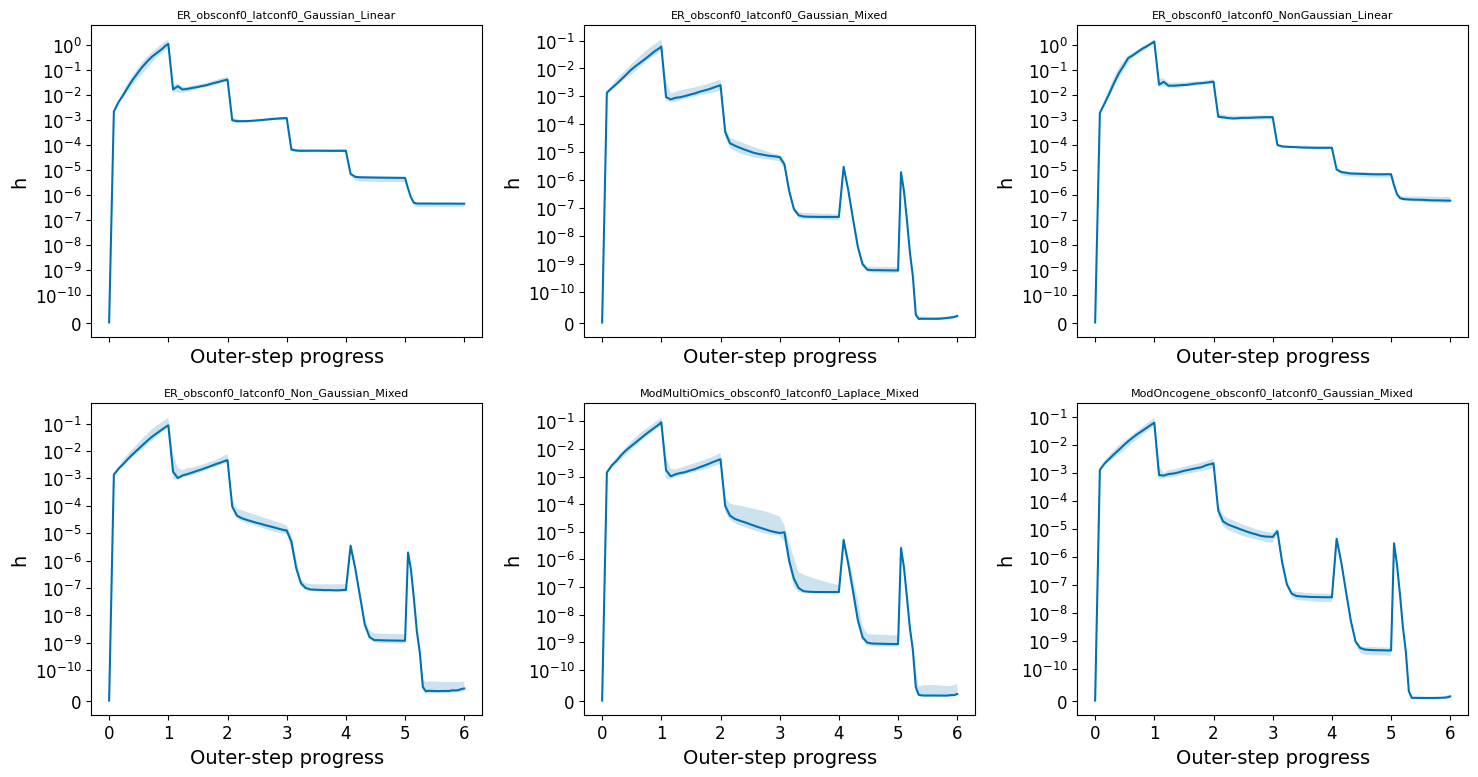

In [3]:
summary = pd.read_pickle(ROOT / "results/analysis/convergence.pkl")["family_summary"]
display(summary.head(20))
for metric in ('relative_objective', 'h'):
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
    for ax, (family, g) in zip(axes.flat, summary.groupby('family')):
        ax.plot(g.progress, g[metric + '_0.5'])
        ax.fill_between(g.progress, g[metric + '_0.25'], g[metric + '_0.75'], alpha=0.2)
        ax.set(title=family.replace('20nodes_', ''), xlabel='Outer-step progress', ylabel=metric)
        ax.title.set_fontsize(8)
        if metric == 'h':
            ax.set_yscale('symlog', linthresh=1e-10)
    fig.tight_layout()
    display(fig)
    plt.close(fig)
